<a href="https://colab.research.google.com/github/mobarak91/Masters-Research-/blob/main/Build_Deep_learning_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Handwritten Digit Recognition Using CNN**

##**1. Import necessary Libraries**

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

## **2. Load Dataset**

In [28]:
# Upload the training dataset
from google.colab import files
uploaded = files.upload()

data = pd.read_csv('/content/train.csv')

# Display dataset dimensions
print(data.shape)

# Display first five rows
data.head()

(42000, 785)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## **3. Separate Features and Labels**

In [30]:
# Separate input features (pixel values)
X = data.drop('label', axis=1)
y = data['label']

# Convert features into NumPy arrays
X = X.values
y = y.values

## **4. Data Normalization and Reshaping**

In [31]:

X = X / 255.0
X = X.reshape(-1, 28, 28, 1)

# Display the new shape
print(X.shape)

(42000, 28, 28, 1)


## **5. Display Sample Images**

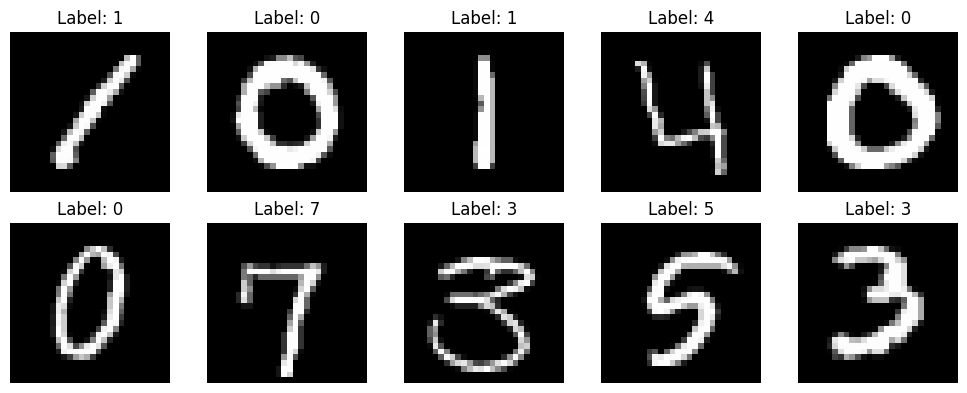

In [32]:
# Create a figure to display sample images
plt.figure(figsize=(10, 4))

# Display first 10 images
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X[i].squeeze(), cmap='gray')
    plt.title(f"Label: {y[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

## **6. Split Training and Validation Data**

In [33]:

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (33600, 28, 28, 1)
Validation data: (8400, 28, 28, 1)


## **7. Build CNN Deep Learning Model**

In [34]:
# Create a Sequential CNN model
model = keras.Sequential([

    # Input layer: 28x28 grayscale image
    layers.Input(shape=(28, 28, 1)),

    # First convolutional layer with 32 filters
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),

    # Reduce image dimensions using max pooling
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer with 64 filters
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),

    # Further reduce feature map dimensions
    layers.MaxPooling2D((2, 2)),

    # Convert 2D feature maps into a 1D vector
    layers.Flatten(),

    # First hidden dense layer with 128 neurons
    layers.Dense(128, activation='relu'),

    # Disable 30% of neurons randomly during training
    layers.Dropout(0.3),

    # Output layer with 10 neurons for digits 0-9
    layers.Dense(10, activation='softmax')
])

# Display model architecture and parameters
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

## **8. Compile the Model**

In [35]:

model.compile(

    # Adam optimizer updates model weights
    optimizer=keras.optimizers.Adam(learning_rate=0.001),

    # Calculate classification error for integer labels
    loss='sparse_categorical_crossentropy',

    # Track model accuracy during training
    metrics=['accuracy']
)

## **9. Train the Model**

In [37]:

history = model.fit(
    X_train,
    y_train,

    # Number of complete passes through training data
    epochs=10,

    # Number of samples processed in each batch
    batch_size=64,

    validation_data=(X_val, y_val)
    )

Epoch 1/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 36s 70ms/step - accuracy: 0.9799 - loss: 0.0695 - val_accuracy: 0.9836 - val_loss: 0.0542
Epoch 2/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 40s 68ms/step - accuracy: 0.9837 - loss: 0.0514 - val_accuracy: 0.9849 - val_loss: 0.0462
Epoch 3/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 29s 56ms/step - accuracy: 0.9871 - loss: 0.0405 - val_accuracy: 0.9875 - val_loss: 0.0410
Epoch 4/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 31s 59ms/step - accuracy: 0.9893 - loss: 0.0338 - val_accuracy: 0.9873 - val_loss: 0.0439
Epoch 5/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 28s 53ms/step - accuracy: 0.9912 - loss: 0.0275 - val_accuracy: 0.9885 - val_loss: 0.0380
Epoch 6/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 39s 50ms/step - accuracy: 0.9924 - loss: 0.0238 - val_accuracy: 0.9890 - val_loss: 0.0375
Epoch 7/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 53s 74ms/step - accuracy: 0.9933 - loss: 0.0199 - val_accuracy: 0.9844 - val_loss: 0.0532
Epoch 8/10
525/525 ━━━━━━━━━━━━━━━━━━━━ 33s 63ms/step - accuracy: 0.9941 - loss: 0.0187 - 

## **10. Evaluate the Model**

In [38]:

val_loss, val_accuracy = model.evaluate(X_val, y_val)

# Print validation accuracy
print("Validation Accuracy:", val_accuracy)

# Print validation loss
print("Validation Loss:", val_loss)

263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9892 - loss: 0.0395
Validation Accuracy: 0.9891666769981384
Validation Loss: 0.039474938064813614


## **11. Visualize Training Performance**

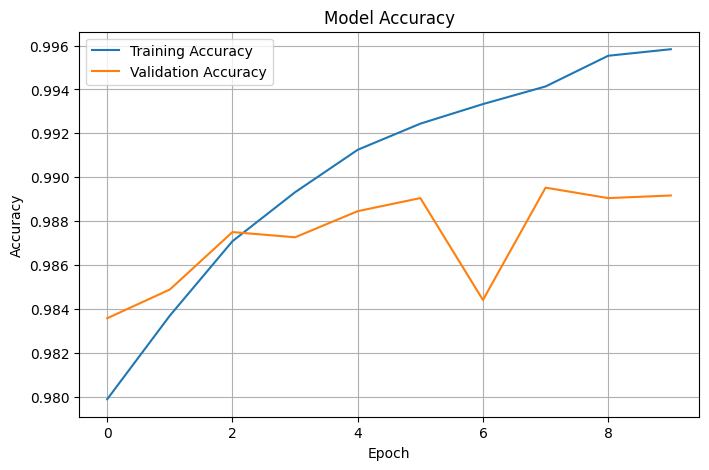

In [39]:
# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid()
plt.show()

## **12. Confusion Matrix**

263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step


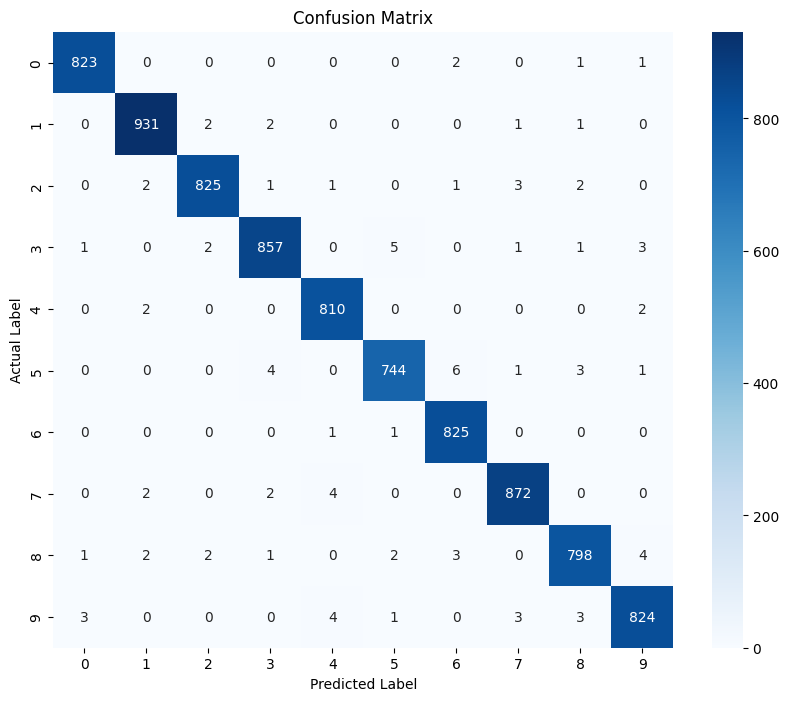

In [40]:

y_prob = model.predict(X_val)
y_pred = np.argmax(y_prob, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

## **13. Classification Report**

In [41]:
# Generate precision, recall and F1-score
print(classification_report(y_val, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       827
           1       0.99      0.99      0.99       937
           2       0.99      0.99      0.99       835
           3       0.99      0.99      0.99       870
           4       0.99      1.00      0.99       814
           5       0.99      0.98      0.98       759
           6       0.99      1.00      0.99       827
           7       0.99      0.99      0.99       880
           8       0.99      0.98      0.98       813
           9       0.99      0.98      0.99       838

    accuracy                           0.99      8400
   macro avg       0.99      0.99      0.99      8400
weighted avg       0.99      0.99      0.99      8400



## **14. Test the Model with Sample Images**

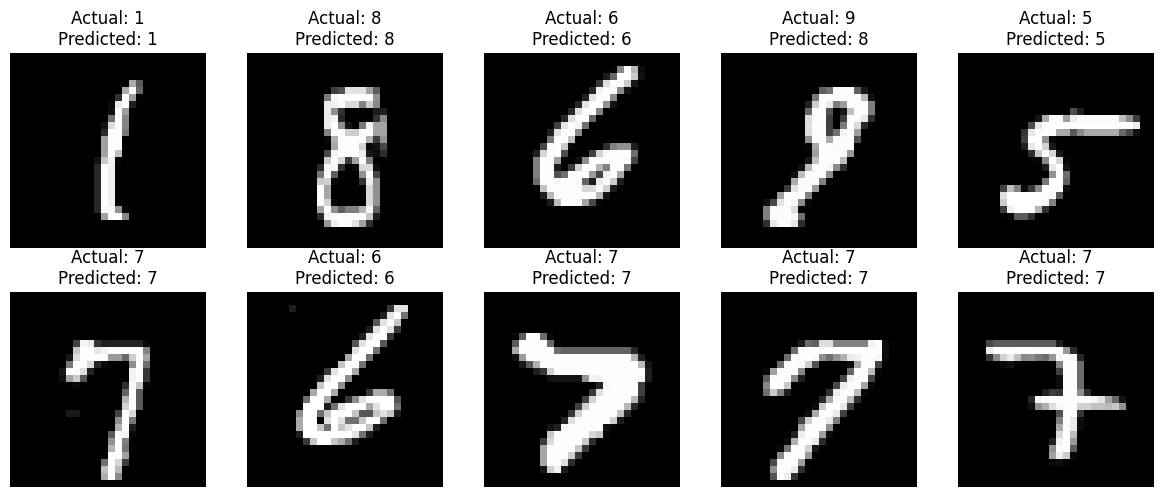

In [42]:
# Display some validation images with predictions
plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    # Display original handwritten digit
    plt.imshow(X_val[i].squeeze(), cmap='gray')

    # Predict digit for the image
    prediction = model.predict(X_val[i:i+1], verbose=0)

    # Get predicted digit
    predicted_digit = np.argmax(prediction)

    # Show actual and predicted labels
    plt.title(f"Actual: {y_val[i]}\nPredicted: {predicted_digit}")

    plt.axis('off')

plt.tight_layout()
plt.show()